In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
adata=sc.datasets.pbmc3k()#和seurat的操作不同，pbmc3k是scanpy的内置数据集，不用添加网址下载
adata.var_names_make_unique()#并非因为不同细胞会测出同一基因，而是在gene这一栏中本就会出现重复（多EsembleID映射到同一Gene Symbol，或同一基因不同转录本等）
print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


这一步加载了Scanpy内置的PBMC3k数据集（这与我在Seurat中操作时需要通过网址下载不同），并且对于重复的基因名进行了区别。

In [2]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")#在基因注释表adata.var中新建一列"mt"，用于标记每个基因是不是线粒体基因，会返回布尔值
sc.pp.calculate_qc_metrics(#pp表示preprocessing，预处理模块。计算质量控制指标
    adata,#AnnData对象
    qc_vars=["mt"],#根据本列
    percent_top=None,#不计算前n基因占比
    log1p=False,#不计算对数转化后的指标
    inplace=True#直接写回adata
)
print(adata.obs[["n_genes_by_counts","total_counts","pct_counts_mt"]].head())
#adata.obs表示细胞注释表，adata.vars表示基因注释表
#取出基因数，总UMI数，线粒体基因占比这3列，在由head()默认取出前5行

                  n_genes_by_counts  total_counts  pct_counts_mt
index                                                           
AAACATACAACCAC-1                781        2421.0       3.015283
AAACATTGAGCTAC-1               1352        4903.0       3.793596
AAACATTGATCAGC-1               1131        3149.0       0.889171
AAACCGTGCTTCCG-1                960        2639.0       1.743085
AAACCGTGTATGCG-1                522         981.0       1.223242


这一步在adata.var基因注释表中添加了mt这一列，判断基因是否属于线粒体基因
接着计算了三个关键的质控指标：
1.n_genes_by_counts：每个细胞检测到的基因数
2.total_counts：每个细胞的总表达量
3.pct_counts_mt：线粒体基因表达占比
最后输出了前5行。index是细胞对应的barcode，实际上就是细胞的标签，代表细胞而不是基因

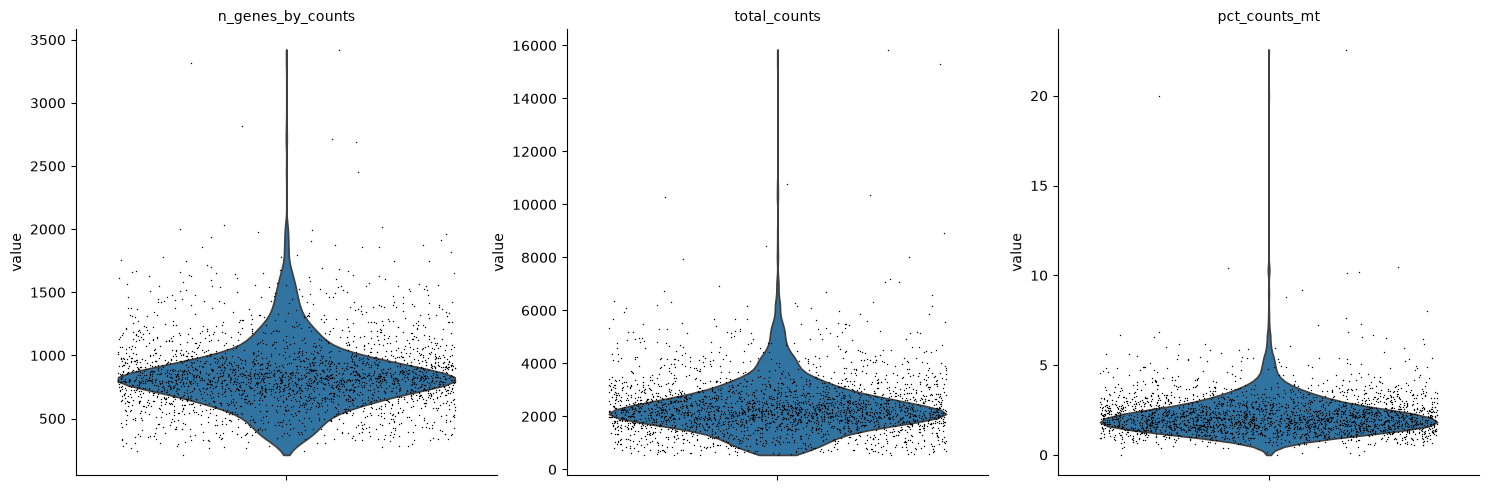

In [3]:
import matplotlib.pyplot as plt#画图库
import os#文件操作库
os.makedirs("../results/figures",#创建保存图片的文件夹。相对目录，取决于我现在的工作目录在哪里
exist_ok=True)#如果该文件夹已存在，不报错
sc.pl.violin(
    adata,
    ["n_genes_by_counts","total_counts","pct_counts_mt"],#要画的三个指标
    jitter=0.4,#每个数据点加一个0.4的随机水平偏移，避免点叠在一起看不清
    multi_panel=True,#每个指标是一个独立的图
    show=False#画完并不立即显示
)
plt.savefig("../results/figures/qc_violin.png",dpi=300,bbox_inches="tight")#保存，分辨率300，自动裁剪多余白边
plt.show()#屏幕上渲染小提琴图

这一步画出了上述三个指标的小提琴图并进行了保存。
观察到大部分细胞的基因数在200到2000之间
观察到大部分细胞的线粒体基因占比在5%以下，但有部分在5%之上
基于图表的分析，我决定在下一步中滤除掉线粒体基因占比在5%以上的细胞。这一步参考了Scanpy的官方教程

In [4]:
print(f"过滤前细胞数:{adata.n_obs}")
sc.pp.filter_cells(adata,min_genes=200)
sc.pp.filter_genes(adata,min_cells=3)
adata=adata[adata.obs.pct_counts_mt<5,:].copy()
print(f"过滤后的细胞数:{adata.n_obs}")

过滤前细胞数:2700
过滤后的细胞数:2643


这一步
过滤掉了低质量的细胞数据（细胞碎片）：至少表达200个基因才能保留。
过滤掉了低质量的基因：至少在3个细胞中表达才能保留。
过滤掉了濒死细胞：线粒体基因比例小于5%才能保留。
原数据集中的2700个细胞滤为了2643个

阶段总结：
完成了数据加载，QC质控，过滤的步骤。
在这阶段中，我了解了AnnData这一数据结构，并且熟悉了Jupyter的使用，它与我之前使用的Pycharm相比有很大的不同。
下一步我将进行归一化和高变基因的筛选。